# Customer Churn Prediction — and What To Do About It

**Lakshman Sai Yaganti — Data Scientist @ Square**

Most churn projects stop at a model. This notebook goes one step further:
after ranking customers by churn risk, it prices the retention campaign and
derives **who is actually worth contacting** from explicit business
assumptions.

Dataset: IBM Telco Customer Churn (7,043 customers, ~26.5% churn).

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

from src.data import load_data
from src.features import split_xy

df = load_data()
print(df.shape)
print(f"Churn rate: {df['Churn'].mean():.1%}")
df.head()

(7043, 22)
Churn rate: 26.5%


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,0-12m
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0,25-48m
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,0-12m
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,25-48m
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,0-12m


## 1 · Exploratory analysis — where does churn live?

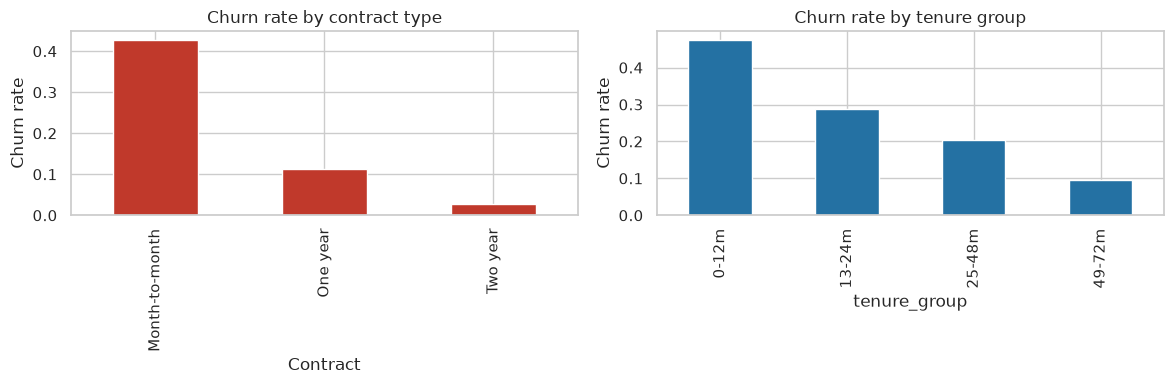

Churn by contract:
Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn, dtype: float64

Churn by tenure group:
tenure_group
0-12m     0.474
13-24m    0.287
25-48m    0.204
49-72m    0.095
Name: Churn, dtype: float64


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

contract = df.groupby("Contract")["Churn"].mean().sort_values(ascending=False)
contract.plot(kind="bar", ax=axes[0], color="#c0392b")
axes[0].set_title("Churn rate by contract type")
axes[0].set_ylabel("Churn rate")

tenure = df.groupby("tenure_group", observed=True)["Churn"].mean()
tenure.plot(kind="bar", ax=axes[1], color="#2471a3")
axes[1].set_title("Churn rate by tenure group")
axes[1].set_ylabel("Churn rate")
plt.tight_layout(); plt.show()

print("Churn by contract:"); print(contract.round(3))
print("\nChurn by tenure group:"); print(tenure.round(3))

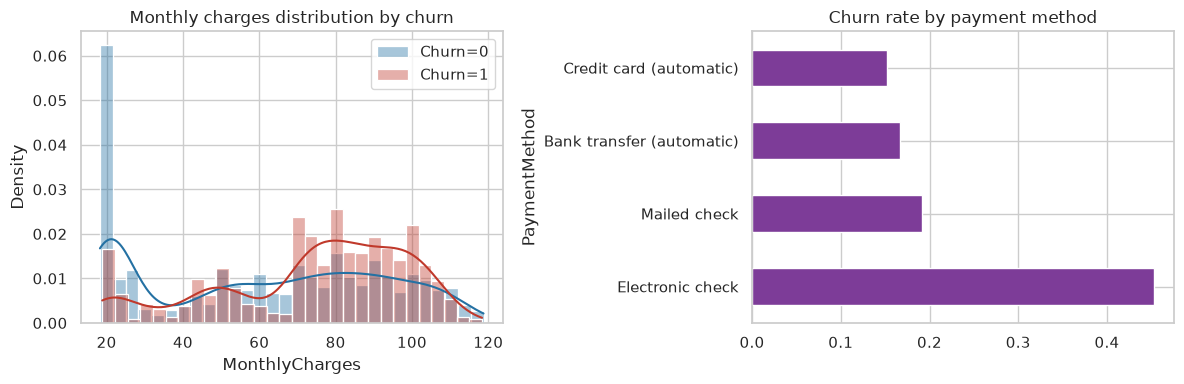

PaymentMethod
Electronic check             0.453
Mailed check                 0.191
Bank transfer (automatic)    0.167
Credit card (automatic)      0.152
Name: Churn, dtype: float64


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for label, color in [(0, "#2471a3"), (1, "#c0392b")]:
    sns.histplot(df[df["Churn"] == label]["MonthlyCharges"], bins=30,
                 kde=True, stat="density", alpha=0.4, label=f"Churn={label}",
                 ax=axes[0], color=color)
axes[0].set_title("Monthly charges distribution by churn")
axes[0].legend()

pay = df.groupby("PaymentMethod")["Churn"].mean().sort_values(ascending=False)
pay.plot(kind="barh", ax=axes[1], color="#7d3c98")
axes[1].set_title("Churn rate by payment method")
plt.tight_layout(); plt.show()
print(pay.round(3))

**What the EDA says**

- **Contract type dominates**: month-to-month customers churn at several
  times the rate of two-year contracts.
- **New customers churn most** — the first year of the relationship is the
  danger zone.
- **Electronic-check payers** churn far more than automatic-payment
  customers, and churners skew toward higher monthly charges (fibre plans
  without add-on services).

## 2 · Modeling — Logistic Regression baseline vs XGBoost

In [4]:
from sklearn.model_selection import train_test_split

from src.train import build_models, RANDOM_STATE
from src.evaluate import classification_metrics, decile_lift_table

X, y = split_xy(df)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

models = build_models(y_train)
probas = {}
rows = []
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    probas[name] = pipe.predict_proba(X_test)[:, 1]
    m = classification_metrics(y_test, probas[name], threshold=0.5)
    m["model"] = name
    rows.append(m)

results = pd.DataFrame(rows)[["model", "roc_auc", "pr_auc", "precision", "recall"]]
results.round(4)

,model,roc_auc,pr_auc,precision,recall
0,logistic_regression,0.8418,0.6363,0.5026,0.7807
1,xgboost,0.8430,0.6596,0.5278,0.7620


## 3 · Decile lift — how concentrated is the risk?

The retention team can only contact a fraction of the base. The decile lift
table answers: *if we contact only the riskiest 10–30%, how much of the
churn do we actually reach?*

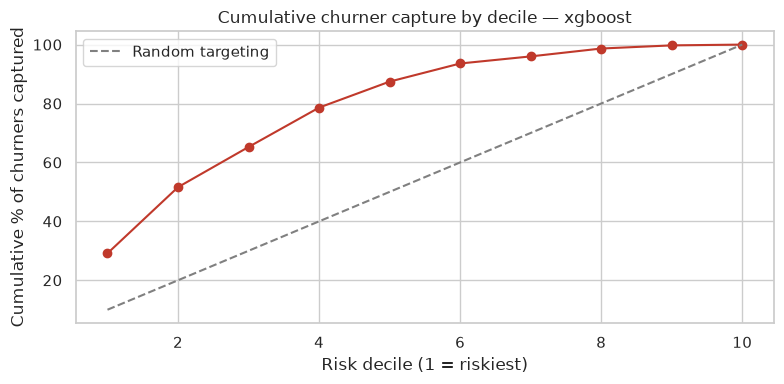

,decile,customers,churners,churn_rate,avg_predicted_risk,capture_rate,cumulative_capture,cumulative_customers_pct,lift
0,1,141,109,0.773,0.904,0.291,0.291,0.1,2.912
1,2,141,84,0.596,0.784,0.225,0.516,0.2,2.244
2,3,141,51,0.362,0.677,0.136,0.652,0.3,1.363
3,4,141,50,0.355,0.553,0.134,0.786,0.4,1.336
4,5,141,33,0.234,0.402,0.088,0.874,0.5,0.882
5,6,140,23,0.164,0.264,0.061,0.936,0.6,0.619
6,7,141,9,0.064,0.157,0.024,0.960,0.7,0.240
7,8,141,10,0.071,0.076,0.027,0.987,0.8,0.267
8,9,141,4,0.028,0.031,0.011,0.997,0.9,0.107
9,10,141,1,0.007,0.011,0.003,1.000,1.0,0.027


In [5]:
best = "xgboost"
lift = decile_lift_table(y_test, probas[best])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(lift["decile"], lift["cumulative_capture"] * 100, marker="o", color="#c0392b")
ax.plot([1, 10], [10, 100], linestyle="--", color="grey", label="Random targeting")
ax.set_xlabel("Risk decile (1 = riskiest)")
ax.set_ylabel("Cumulative % of churners captured")
ax.set_title(f"Cumulative churner capture by decile — {best}")
ax.legend(); plt.tight_layout(); plt.show()

lift.round(3)

## 4 · Why does the model flag a customer? (SHAP)

/home/hatch/workspace/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


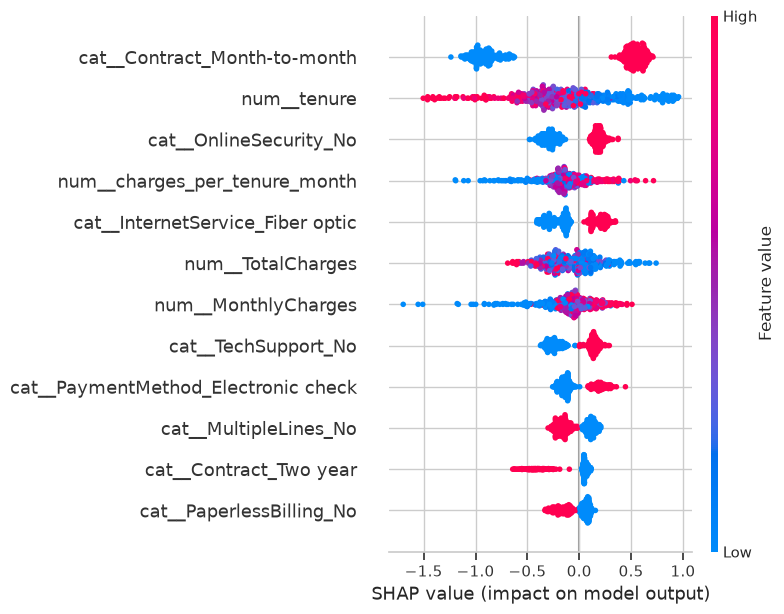

cat__Contract_Month-to-month           0.7062
num__tenure                            0.4018
cat__OnlineSecurity_No                 0.2362
num__charges_per_tenure_month          0.2184
cat__InternetService_Fiber optic       0.2060
num__TotalCharges                      0.2010
num__MonthlyCharges                    0.1949
cat__TechSupport_No                    0.1924
cat__PaymentMethod_Electronic check    0.1604
cat__MultipleLines_No                  0.1428
dtype: float32


In [6]:
import shap

pipe = models[best]
pre = pipe.named_steps["preprocessor"]
clf = pipe.named_steps["model"]
X_test_t = pre.transform(X_test)
feature_names = pre.get_feature_names_out()

explainer = shap.TreeExplainer(clf)
sample = X_test_t[:500]
shap_values = explainer.shap_values(sample)

plt.figure()
shap.summary_plot(shap_values, sample, feature_names=feature_names,
                  max_display=12, show=False)
plt.tight_layout(); plt.show()

importance = pd.Series(np.abs(shap_values).mean(axis=0), index=feature_names)
print(importance.sort_values(ascending=False).head(10).round(4))

## 5 · Retention economics — from probabilities to a decision

Stated assumptions (from `src/retention.py` — planning assumptions, not
measured data):

- Retention offer cost: **$20** per contacted customer
- Save probability: **30%** of would-be churners accept and stay
- Customer value: **$65/month × 12 months** retained = **$780 CLV**

Break-even rule: contact only when `p(churn) × 0.30 × $780 > $20`,
i.e. **p(churn) > 8.5%**.

In [7]:
from src.retention import campaign_impact, impact_table

impact = campaign_impact(y_test, probas[best])
print("Break-even threshold:", round(impact["assumptions"]["breakeven_threshold"], 4))
print(f"Evaluated on {impact['evaluated_on_customers']} test customers "
      f"with {impact['total_actual_churners']} actual churners\n")
impact_table(impact).round(1)

Break-even threshold: 0.0855
Evaluated on 1409 test customers with 374 actual churners



,strategy,customers_contacted,pct_of_base_contacted,actual_churners_reached,est_customers_saved,est_gross_saved_value,campaign_cost,est_net_benefit
0,target_top_decile,141,10.0,109,32.7,25506.0,2820.0,22686.0
1,target_ev_optimal,1028,73.0,363,108.9,84942.0,20560.0,64382.0
2,blanket,1409,100.0,374,112.2,87516.0,28180.0,59336.0


## 6 · Conclusions

- XGBoost out-ranks the logistic baseline on PR-AUC, and the decile table
  shows churn risk is heavily concentrated in the top deciles — targeted
  outreach reaches most churners while contacting a minority of the base.
- Under the stated assumptions, the EV-optimal strategy (contact everyone
  above the ~8.5% break-even probability) beats both top-decile-only and
  blanket outreach on estimated net benefit.
- The model's top drivers (contract, tenure, payment method, add-on
  services) are all levers the business actually controls — which is what
  makes this a retention strategy, not just a score.